# Chapitre 4 - Cours 3 : Sélectionner un modèle

On ne cherche pas le meilleur modèle dans l'absolu, mais **le meilleur modèle pour son
application**. Ce notebook suit la section *Model Selection* du livre :

1. le workflow de sélection (section *Model Selection Workflow*) ;
2. filtres durs, attributs souples et front de Pareto ;
3. open source, poids ouverts et licences (section *Open source, open weight, and model licenses*) ;
4. API ou auto-hébergement : les sept axes (section *Open source models versus model APIs*) ;
5. construire ou acheter : le calcul du point mort (section *API cost versus engineering cost*) ;
6. agréger des benchmarks en classement (section *Benchmark selection and aggregation*) ;
7. les corrélations entre benchmarks ;
8. la contamination des données (section *Data contamination with public benchmarks*) ;
9. la saturation des benchmarks.

Les chiffres de catalogue, de prix et de classements sont **fictifs mais plausibles** ; seule
la matrice de corrélation (tableau 4-5 du livre) est une donnée réelle. Le seul modèle
utilisé est Qwen 0.5B, pour la détection de contamination par perplexité.

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from matplotlib.ticker import FuncFormatter
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.width", 140)
rng = np.random.default_rng(0)
plain = FuncFormatter(lambda v, _: f"{v:g}")   # graduations lisibles sur les axes logarithmiques

## 1. Le workflow de sélection (section *Model Selection Workflow*)

La sélection de modèle n'a pas lieu une seule fois : on la refait à chaque étape
d'adaptation (prompt engineering, affinage...). Typiquement, on commence avec le modèle le
plus fort pour vérifier la **faisabilité**, puis on redescend vers des modèles plus petits ;
ou, pour l'affinage, on débogue sur un petit modèle avant de monter. Dans tous les cas, deux
questions : quelle est la meilleure performance atteignable, et quel modèle offre le meilleur
rapport performance / coût ?

Le livre distingue :

- les **attributs durs**, impossibles ou irréalistes à changer : licence, données
  d'entraînement, taille, politique de confidentialité de votre entreprise ;
- les **attributs souples**, améliorables : exactitude, toxicité, cohérence factuelle
  (un découpage de la tâche en deux étapes peut faire passer l'exactitude de 20 % à 70 %).

Le statut dépend du contexte : la latence est souple si vous hébergez le modèle (vous pouvez
l'optimiser), dure si vous passez par l'API d'un tiers. Le workflow comporte quatre étapes
**itératives** :

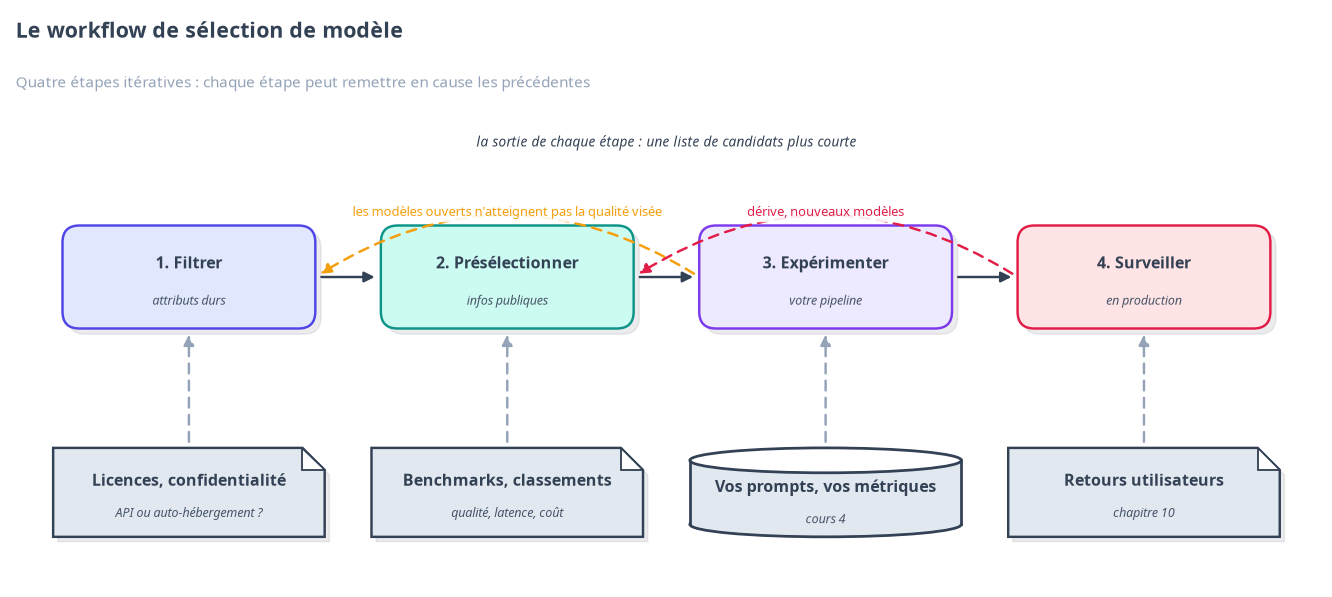

In [2]:
d = Diagram(14, 5.2, title="Le workflow de sélection de modèle",
            subtitle="Quatre étapes itératives : chaque étape peut remettre en cause les précédentes")
d.box("s1", 1.9, 3.3, "1. Filtrer", sub="attributs durs", color=INDIGO, w=2.7, h=1.1)
d.box("s2", 5.3, 3.3, "2. Présélectionner", sub="infos publiques", color=TEAL, w=2.7, h=1.1)
d.box("s3", 8.7, 3.3, "3. Expérimenter", sub="votre pipeline", color=VIOLET, w=2.7, h=1.1)
d.box("s4", 12.1, 3.3, "4. Surveiller", sub="en production", color=ROSE, w=2.7, h=1.1)
d.box("i1", 1.9, 1.0, "Licences, confidentialité", sub="API ou auto-hébergement ?", color=SLATE, kind="doc", w=2.9, h=0.95)
d.box("i2", 5.3, 1.0, "Benchmarks, classements", sub="qualité, latence, coût", color=SLATE, kind="doc", w=2.9, h=0.95)
d.box("i3", 8.7, 1.0, "Vos prompts, vos métriques", sub="cours 4", color=SLATE, kind="db", w=2.9, h=0.95)
d.box("i4", 12.1, 1.0, "Retours utilisateurs", sub="chapitre 10", color=SLATE, kind="doc", w=2.9, h=0.95)
for a, b in [("s1", "s2"), ("s2", "s3"), ("s3", "s4")]:
    d.arrow(a, b)
for a, b in [("i1", "s1"), ("i2", "s2"), ("i3", "s3"), ("i4", "s4")]:
    d.arrow(a, b, style="dashed", color=GRAY)
d.arrow("s3", "s1", "les modèles ouverts n'atteignent pas la qualité visée", style="dashed", color=AMBER, rad=0.32,
        label_offset=(0, 0.05))
d.arrow("s4", "s2", "dérive, nouveaux modèles", style="dashed", color=ROSE, rad=0.32, label_offset=(0, 0.05))
d.note(7.0, 4.75, "la sortie de chaque étape : une liste de candidats plus courte", color=SLATE)
d.show()

> **À retenir.** Filtrez d'abord sur ce qui n'est pas négociable (attributs durs), utilisez
> l'information publique pour présélectionner, tranchez avec votre propre pipeline, puis
> surveillez. La boucle est itérative : une découverte tardive peut rouvrir un choix précoce.

## 2. Filtres durs, attributs souples, front de Pareto (section *Model Selection Workflow*)

Prenons un catalogue fictif de 12 modèles, et une application interne d'une entreprise
européenne avec les exigences dures suivantes : données hébergées en UE (ou poids ouverts,
pour un hébergement interne), usage commercial autorisé, contexte d'au moins 32 000 tokens,
TTFT P90 inférieur à 400 ms.

In [3]:
cat = c4.CATALOGUE.copy()
rules = {
    "données hors UE": lambda d: d.donnees_ue | d.poids_ouverts,
    "licence non commerciale": lambda d: d.usage_commercial,
    "contexte < 32k": lambda d: d.contexte_k >= 32,
    "TTFT P90 > 400 ms": lambda d: d.ttft_p90_ms <= 400,
}
filt = c4.hard_filter(cat, rules)
filt[["modele", "poids_ouverts", "usage_commercial", "contexte_k", "ttft_p90_ms", "donnees_ue",
      "prix_sortie", "qualite", "elimine_par"]]

,modele,poids_ouverts,usage_commercial,contexte_k,ttft_p90_ms,donnees_ue,prix_sortie,qualite,elimine_par
0,Atlas-XL,False,True,200,450,False,15.00,88,données hors UE
1,Atlas-M,False,True,128,220,False,3.00,81,données hors UE
2,Atlas-S,False,True,128,120,False,0.60,72,données hors UE
3,Borealis-70B,True,True,128,300,True,0.90,80,
4,Borealis-8B,True,True,128,90,True,0.20,66,
5,Cirrus-34B,True,False,32,200,True,0.50,76,licence non commerciale
6,Cirrus-7B,True,False,32,80,True,0.15,63,licence non commerciale
7,Delta-Pro,False,True,1000,600,True,10.00,86,TTFT P90 > 400 ms
8,Delta-Flash,False,True,1000,150,True,0.40,74,
9,Equinox-14B,True,True,64,130,True,0.30,71,


Parmi les survivants, la décision porte sur des attributs souples qui s'arbitrent : la
qualité (ici un score interne) contre le coût. Un modèle est **dominé** s'il existe un autre
modèle au moins aussi bon sur les deux axes et strictement meilleur sur l'un. Les modèles non
dominés forment le **front de Pareto** : le seul ensemble où il est rationnel de choisir.

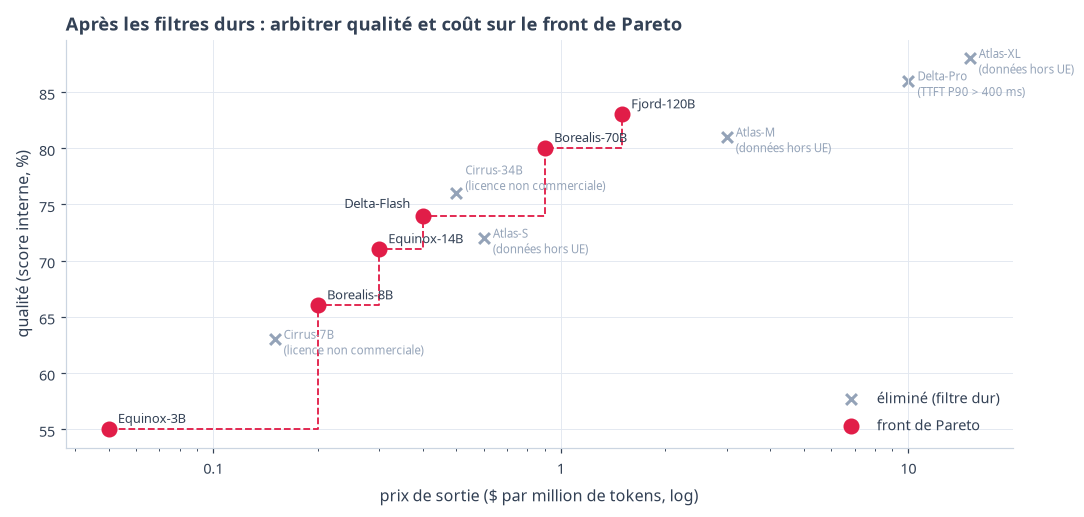

In [4]:
ok = filt[filt.elimine_par == ""].reset_index(drop=True)
front = c4.pareto_front(ok.prix_sortie, ok.qualite)
fig, ax = plt.subplots(figsize=(10, 4.8))
elim = filt[filt.elimine_par != ""]
ax.scatter(elim.prix_sortie, elim.qualite, color=GRAY, s=50, marker="x", label="éliminé (filtre dur)")
for _, r in elim.iterrows():
    ax.annotate(f"{r.modele}\n({r.elimine_par})", (r.prix_sortie, r.qualite), fontsize=7.5, color=GRAY,
                xytext=(6, 2) if r.modele == "Cirrus-34B" else (6, -10), textcoords="offset points")
if (~front).any():
    ax.scatter(ok.prix_sortie[~front], ok.qualite[~front], color=SKY, s=70, label="candidat dominé")
ax.scatter(ok.prix_sortie[front], ok.qualite[front], color=ROSE, s=90, label="front de Pareto", zorder=3)
fr = ok[front].sort_values("prix_sortie")
ax.step(fr.prix_sortie, fr.qualite, where="post", color=ROSE, lw=1.2, ls="--")
for _, r in ok.iterrows():
    left = r.modele in ("Delta-Flash",)
    ax.annotate(r.modele, (r.prix_sortie, r.qualite), fontsize=8.5, xytext=(-8, 5) if left else (6, 4),
                textcoords="offset points", ha="right" if left else "left")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(plain); ax.set_xlabel("prix de sortie ($ par million de tokens, log)")
ax.set_ylabel("qualité (score interne, %)"); ax.legend(loc="lower right")
ax.set_title("Après les filtres durs : arbitrer qualité et coût sur le front de Pareto")
plt.tight_layout(); plt.show()

Le front se lit comme un menu : chaque pas vers la droite achète des points de qualité à un
certain prix. Le choix final dépend de la valeur d'un point de qualité pour votre métier
(cours 4 : relier métriques d'évaluation et métriques métier). Un candidat dominé n'est
jamais le bon choix, sauf attribut non modélisé ici (communauté, support, feuille de route).

> **À retenir.** Filtres durs d'abord (éliminatoires), puis arbitrage multi-objectif sur
> les attributs souples : seul le front de Pareto mérite d'être considéré.

## 3. Open source, poids ouverts et licences (section *Open source, open weight, and model licenses*)

Le terme « open source » est disputé. Le livre distingue les modèles à **poids ouverts**
(*open weight* : on peut télécharger les poids, pas les données) des modèles **ouverts**
(*open model* : données d'entraînement publiques aussi). La plupart des modèles dits
« open source » ne sont qu'à poids ouverts. Les données ouvertes permettent de réentraîner,
d'auditer (le modèle a-t-il été entraîné sur des données illégalement acquises ?) et de
comprendre le modèle.

Les **licences** ajoutent une couche : beaucoup de modèles ont leur propre licence. Trois
questions à se poser systématiquement :

| Question | Exemple cité par le livre |
|---|---|
| L'usage commercial est-il autorisé ? | le premier Llama était sous licence non commerciale |
| S'il l'est, avec quelles restrictions ? | Llama 2 et 3 : licence spéciale au-delà de 700 millions d'utilisateurs actifs mensuels |
| Peut-on utiliser les sorties pour entraîner d'autres modèles ? | important pour la distillation et les données synthétiques (chapitre 8) |

Enfin, la **lignée des données** compte : un modèle entraîné sur les sorties d'un autre
modèle dont la licence l'interdit hérite du problème, quelle que soit sa propre licence.